In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install patchify
!pip install -U segmentation-models

  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.0 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.2
    Uninstalling numpy-2.5.2:
      Successfully uninstalled numpy-2.5.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python-headless 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you have numpy 1.26.4 which is i

  Using cached numpy-2.5.2-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.2-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
             ^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/commands/install.py", line 447, in run
^C


In [ ]:
!pip install segmentation-models

  Using cached numpy-2.5.2-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.2-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
patchify 0.2.3 requires numpy<2,>=1, but you have numpy 2.5.2 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.5.2 which is incompatible.


In [ ]:
import os
os.environ["SM_FRAMEWORK"] = "tf.keras"

import cv2
import numpy as np

from matplotlib import pyplot as plt
from patchify import patchify
from PIL import Image
import segmentation_models as sm
from tensorflow.keras.metrics import MeanIoU
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from tensorflow import keras
from keras import backend as K
import keras

Segmentation Models: using `tf.keras` framework.


In [ ]:
scaler = MinMaxScaler()
root_directory = '/content/drive/MyDrive/Semantic segmentation dataset/Tile 1'
patch_size = 256

In [ ]:
image_dataset = []
for path, subdirs, files in os.walk(root_directory):
    #print(path)
    dirname = path.split(os.path.sep)[-1]
    #/content/drive/MyDrive/Semantic segmentation dataset/Tile 1/images/image_part_001.jpg
    #print(dirname,end='\t')
    if dirname == 'images':
        images = os.listdir(path)
        print(images) #List of all image names in this subdirectory
        for i, image_name in enumerate(images):
            if image_name.endswith(".jpg"):   #Only read jpg images...

                image = cv2.imread(path+"/"+image_name, 1)  #Read each image as BGR
                SIZE_X = (image.shape[1]//patch_size)*patch_size #Nearest size divisible by our patch size
                SIZE_Y = (image.shape[0]//patch_size)*patch_size #Nearest size divisible by our patch size
                image = Image.fromarray(image)
                image = image.crop((0 ,0, SIZE_X, SIZE_Y))  #Crop from top left corner
                #image = image.resize((SIZE_X, SIZE_Y))  #Try not to resize for semantic segmentation
                image = np.array(image)

                #Extract patches from each image
                print("Now patchifying image:", path+"/"+image_name)
                patches_img = patchify(image, (patch_size, patch_size, 3), step=patch_size)  #Step=256 for 256 patches means no overlap

                for i in range(patches_img.shape[0]):
                    for j in range(patches_img.shape[1]):

                        single_patch_img = patches_img[i,j,:,:]

                        #Use minmaxscaler instead of just dividing by 255.
                        single_patch_img = scaler.fit_transform(single_patch_img.reshape(-1, single_patch_img.shape[-1])).reshape(single_patch_img.shape)

                        #single_patch_img = (single_patch_img.astype('float32')) / 255.
                        single_patch_img = single_patch_img[0] #Drop the extra unecessary dimension that patchify adds.
                        image_dataset.append(single_patch_img)

['image_part_002.jpg', 'image_part_009.jpg', 'image_part_008.jpg', 'image_part_005.jpg', 'image_part_006.jpg', 'image_part_004.jpg', 'image_part_007.jpg', 'image_part_001.jpg', 'image_part_003.jpg']
Now patchifying image: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/images/image_part_002.jpg
Now patchifying image: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/images/image_part_009.jpg
Now patchifying image: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/images/image_part_008.jpg
Now patchifying image: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/images/image_part_005.jpg
Now patchifying image: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/images/image_part_006.jpg
Now patchifying image: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/images/image_part_004.jpg
Now patchifying image: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/images/image_part_007.jpg
Now patchifying image: /content/drive/

In [ ]:
image_dataset

[array([[[0.94117647, 0.90196078, 0.8745098 ],
         [0.92156863, 0.88235294, 0.85490196],
         [0.95686275, 0.90980392, 0.90196078],
         ...,
         [0.86666667, 0.83921569, 0.85098039],
         [0.81960784, 0.77254902, 0.79607843],
         [0.8745098 , 0.83137255, 0.84313725]],
 
        [[1.        , 0.97254902, 0.95686275],
         [0.98431373, 0.94117647, 0.9254902 ],
         [0.97254902, 0.9254902 , 0.91764706],
         ...,
         [0.83137255, 0.80392157, 0.81568627],
         [0.80392157, 0.75686275, 0.78039216],
         [0.88235294, 0.83921569, 0.85098039]],
 
        [[0.99215686, 0.95686275, 0.94509804],
         [0.94901961, 0.91372549, 0.90196078],
         [0.94509804, 0.90980392, 0.89803922],
         ...,
         [0.83529412, 0.80784314, 0.81960784],
         [0.79607843, 0.74901961, 0.77254902],
         [0.85882353, 0.81568627, 0.82745098]],
 
        ...,
 
        [[0.83137255, 0.80784314, 0.78823529],
         [0.78823529, 0.76078431, 0.74901

In [ ]:
 #Now do the same as above for masks
 #For this specific dataset we could have added masks to the above code as masks have extension png
mask_dataset = []
for path, subdirs, files in os.walk(root_directory):
    #print(path)
    dirname = path.split(os.path.sep)[-1]
    if dirname == 'masks':   #Find all 'images' directories
        masks = os.listdir(path)  #List of all image names in this subdirectory
        for i, mask_name in enumerate(masks):
            if mask_name.endswith(".png"):   #Only read png images... (masks in this dataset)

                mask = cv2.imread(path+"/"+mask_name, 1)  #Read each image as Grey (or color but remember to map each color to an integer)
                mask = cv2.cvtColor(mask,cv2.COLOR_BGR2RGB)
                SIZE_X = (mask.shape[1]//patch_size)*patch_size #Nearest size divisible by our patch size
                SIZE_Y = (mask.shape[0]//patch_size)*patch_size #Nearest size divisible by our patch size
                mask = Image.fromarray(mask)
                mask = mask.crop((0 ,0, SIZE_X, SIZE_Y))  #Crop from top left corner
                #mask = mask.resize((SIZE_X, SIZE_Y))  #Try not to resize for semantic segmentation
                mask = np.array(mask)

                #Extract patches from each image
                print("Now patchifying mask:", path+"/"+mask_name)
                patches_mask = patchify(mask, (patch_size, patch_size, 3), step=patch_size)  #Step=256 for 256 patches means no overlap

                for i in range(patches_mask.shape[0]):
                    for j in range(patches_mask.shape[1]):

                        single_patch_mask = patches_mask[i,j,:,:]
                        #single_patch_img = (single_patch_img.astype('float32')) / 255. #No need to scale masks, but you can do it if you want
                        single_patch_mask = single_patch_mask[0] #Drop the extra unecessary dimension that patchify adds.
                        mask_dataset.append(single_patch_mask)

Now patchifying mask: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/masks/image_part_003.png
Now patchifying mask: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/masks/image_part_004.png
Now patchifying mask: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/masks/image_part_005.png
Now patchifying mask: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/masks/image_part_008.png
Now patchifying mask: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/masks/image_part_006.png
Now patchifying mask: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/masks/image_part_007.png
Now patchifying mask: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/masks/image_part_009.png
Now patchifying mask: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/masks/image_part_002.png
Now patchifying mask: /content/drive/MyDrive/Semantic segmentation dataset/Tile 1/masks/image_part_001.png


In [ ]:
image_dataset = np.array(image_dataset)
mask_dataset =  np.array(mask_dataset)

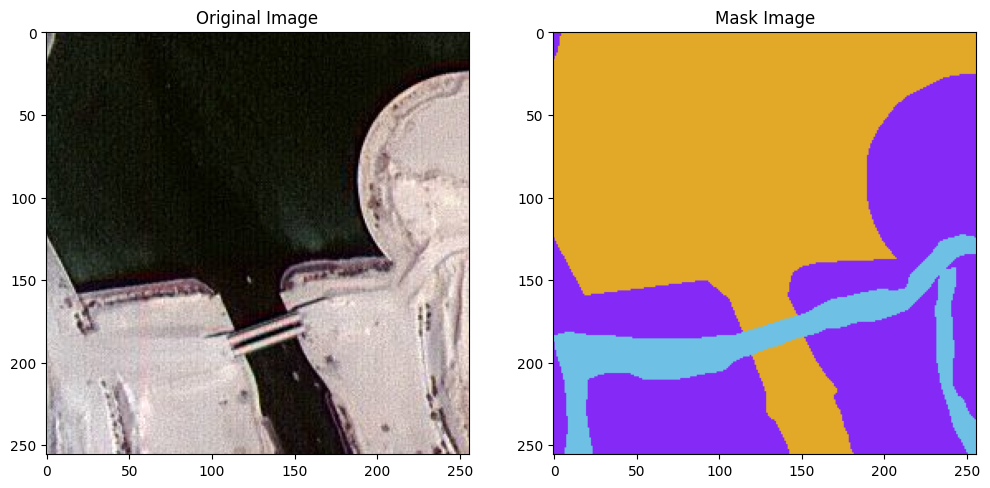

In [ ]:
#Sanity check, view few images
import random
import numpy as np
image_number = random.randint(0, len(image_dataset))
plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.title("Original Image")
plt.imshow(np.reshape(image_dataset[image_number], (patch_size, patch_size, 3)))
plt.subplot(122)
plt.imshow(np.reshape(mask_dataset[image_number], (patch_size, patch_size, 3)))
plt.title("Mask Image")
plt.show()

#Building: #3C1098 (Royal Purple)
#Land (unpaved area): #8429F6 (Vibrant Purple)
#Road: #6EC1E4. #Sky Blue
#Vegetation: #FEDD3A #warm shade of yellow
#Water: #E2A929 #Orange
#Unlabeled: #9B9B9B #Gray.


In [ ]:
#Convert HEX to RGB array
# Try the following to understand how python handles hex values...
a=int('3C', 16)  #3C with base 16. Should return 60.
print(a)
#Do the same for all RGB channels in each hex code to convert to RGB
Building = '#3C1098'.lstrip('#')
Building = np.array(tuple(int(Building[i:i+2], 16) for i in (0, 2, 4))) # 60, 16, 152

Land = '#8429F6'.lstrip('#')
Land = np.array(tuple(int(Land[i:i+2], 16) for i in (0, 2, 4))) #132, 41, 246

Road = '#6EC1E4'.lstrip('#')
Road = np.array(tuple(int(Road[i:i+2], 16) for i in (0, 2, 4))) #110, 193, 228

Vegetation =  'FEDD3A'.lstrip('#')  #Bright, warm shade of Yellow
Vegetation = np.array(tuple(int(Vegetation[i:i+2], 16) for i in (0, 2, 4))) #254, 221, 58

Water = 'E2A929'.lstrip('#')
Water = np.array(tuple(int(Water[i:i+2], 16) for i in (0, 2, 4))) #226, 169, 41

Unlabeled = '#9B9B9B'.lstrip('#')
Unlabeled = np.array(tuple(int(Unlabeled[i:i+2], 16) for i in (0, 2, 4))) #155, 155, 155

label = single_patch_mask

60


In [ ]:
def rgb_to_2D_label(label):
    """
    Suply our labale masks as input in RGB format.
    Replace pixels with specific RGB values ...
    """
    label_seg = np.zeros(label.shape,dtype=np.uint8)
    label_seg [np.all(label == Building,axis=-1)] = 0
    label_seg [np.all(label==Land,axis=-1)] = 1
    label_seg [np.all(label==Road,axis=-1)] = 2
    label_seg [np.all(label==Vegetation,axis=-1)] = 3
    label_seg [np.all(label==Water,axis=-1)] = 4
    label_seg [np.all(label==Unlabeled,axis=-1)] = 5

    label_seg = label_seg[:,:,0]  #Just take the first channel, no need for all 3 channels

    return label_seg

In [ ]:
labels = []
for i in range(mask_dataset.shape[0]):
    label = rgb_to_2D_label(mask_dataset[i])
    labels.append(label)

In [ ]:
labels = np.array(labels)
labels
labels = np.expand_dims(labels, axis=3)

In [ ]:
print("Unique labels in label dataset are: ", np.unique(labels))

Unique labels in label dataset are:  [0 1 2 3 4 5]


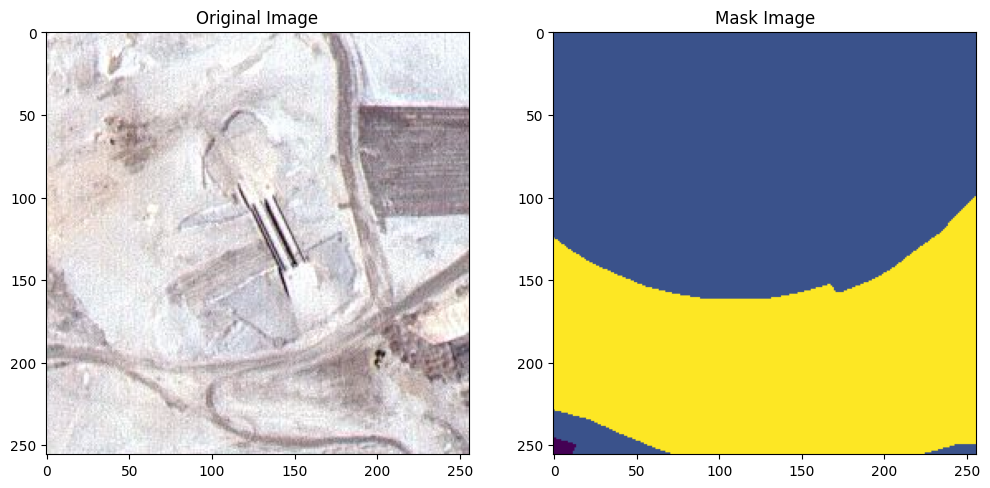

In [ ]:
#Another Sanity check, view few images
import random
import numpy as np
image_number = random.randint(0, len(image_dataset))
plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.title("Original Image")
plt.imshow(image_dataset[image_number])
plt.subplot(122)
plt.imshow(labels[image_number][:,:,0])
plt.title("Mask Image")
plt.show()

In [ ]:
#print(labels)
n_classes = len(np.unique(labels))
print(n_classes)
from keras.utils import to_categorical
labels_cat = to_categorical(labels, num_classes=n_classes)
print(type(labels_cat))
print(type(y_train))
print(y_train.dtype)
print("Shape of Labels Cat",labels_cat.shape)

6
<class 'numpy.ndarray'>


NameError: name 'y_train' is not defined

In [ ]:
image_dataset = np.array(image_dataset, dtype=np.float32)
labels_cat = np.array(labels_cat, dtype=np.float32)
print("Image Dataset Shape",image_dataset.shape)
print("labels Shape",labels_cat.shape)
#print(labels_cat[2])

Image Dataset Shape (54, 256, 256, 3)
labels Shape (54, 256, 256, 6)


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(image_dataset, labels_cat, test_size=0.20, random_state=42)

In [ ]:
weights = [0.1666, 0.1666, 0.1666, 0.1666, 0.1666, 0.1666]
dice_loss = sm.losses.DiceLoss(class_weights=weights)
focal_loss = sm.losses.CategoricalFocalLoss()
total_loss = dice_loss + (1 * focal_loss)

In [ ]:
IMG_HEIGHT = X_train.shape[1]
IMG_WIDTH  = X_train.shape[2]
IMG_CHANNELS = X_train.shape[3]
print(IMG_CHANNELS)

3


In [ ]:
!pip install import-ipynb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 16.4 MB/s eta 0:00:00


In [ ]:
def jacard_coef(y_true, y_pred):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    #y_true_f = keras.ops.flatten(y_true)
    #y_pred_f = keras.ops.flatten(y_pred)
    intersection = keras.ops.sum(y_true_f * y_pred_f)
    return (intersection + 1.0) / (keras.ops.sum(y_true_f) + keras.ops.sum(y_pred_f) - intersection + 1.0)

In [ ]:
import import_ipynb
import UnetModel
from UnetModel import multi_unet_model

In [ ]:
metrics=['accuracy', jacard_coef]

In [ ]:
def get_model():
    return multi_unet_model(n_classes=n_classes, IMG_HEIGHT=IMG_HEIGHT, IMG_WIDTH=IMG_WIDTH, IMG_CHANNELS=IMG_CHANNELS)

In [ ]:
model = get_model()
model.compile(optimizer='adam', loss=total_loss, metrics=metrics)
#model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=metrics)
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 256, 256,  │        448 │ input_layer_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 256, 256,  │          0 │ conv2d_19[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 256, 256,  │      2,320 │ dropout_9[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 128, 128,  │          0 │ conv2d_20[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │      4,640 │ max_pooling2d_4[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 128, 128,  │          0 │ conv2d_21[0][0]   │
│ (Dropout)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │      9,248 │ dropout_10[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 64, 64,    │          0 │ conv2d_22[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_5[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 64, 64,    │          0 │ conv2d_23[0][0]   │
│ (Dropout)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 64, 64,    │     36,928 │ dropout_11[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 32, 32,    │          0 │ conv2d_24[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_6[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 32, 32,    │          0 │ conv2d_25[0][0]   │
│ (Dropout)           │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 32, 32,    │    147,584 │ dropout_12[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 16, 16,    │          0 │ conv2d_26[0][0] 

 Total params: 1,941,190 (7.41 MB)

 Trainable params: 1,941,190 (7.41 MB)

 Non-trainable params: 0 (0.00 B)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 256, 256,  │        448 │ input_layer_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 256, 256,  │          0 │ conv2d_19[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 256, 256,  │      2,320 │ dropout_9[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 128, 128,  │          0 │ conv2d_20[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │      4,640 │ max_pooling2d_4[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 128, 128,  │          0 │ conv2d_21[0][0]   │
│ (Dropout)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │      9,248 │ dropout_10[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 64, 64,    │          0 │ conv2d_22[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_5[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 64, 64,    │          0 │ conv2d_23[0][0]   │
│ (Dropout)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 64, 64,    │     36,928 │ dropout_11[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 32, 32,    │          0 │ conv2d_24[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_6[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 32, 32,    │          0 │ conv2d_25[0][0]   │
│ (Dropout)           │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 32, 32,    │    147,584 │ dropout_12[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 16, 16,    │          0 │ conv2d_26[0][0] 

 Total params: 1,941,190 (7.41 MB)

 Trainable params: 1,941,190 (7.41 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# Verify no array is empty
assert X_train.size > 0, "X_train is empty!"
assert y_train.size > 0, "y_train is empty!"
assert X_test.size > 0, "X_test is empty!"
assert y_test.size > 0, "y_test is empty!"

In [ ]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (43, 256, 256, 3)
y_train shape: (43, 256, 256, 6)
X_test shape: (11, 256, 256, 3)
y_test shape: (11, 256, 256, 6)


In [ ]:
print(len(X_train), len(y_train))
print(X_train.shape, y_train.shape)
print("Any NaN in X_train:", np.isnan(X_train).any())
print("Any NaN in y_train:", np.isnan(y_train).any())

43 43
(43, 256, 256, 3) (43, 256, 256, 6)
Any NaN in X_train: False
Any NaN in y_train: False


In [ ]:
history1 = model.fit(X_train, y_train, batch_size = 16, verbose=1, epochs=15, shuffle=False)

Epoch 1/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 49s 12s/step - accuracy: 0.1073 - jacard_coef: 0.0812 - loss: 1.0425
Epoch 2/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 36s 10s/step - accuracy: 0.2549 - jacard_coef: 0.0963 - loss: 1.0302
Epoch 3/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 40s 10s/step - accuracy: 0.4042 - jacard_coef: 0.1056 - loss: 1.0265
Epoch 4/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 41s 10s/step - accuracy: 0.5111 - jacard_coef: 0.1207 - loss: 1.0225
Epoch 5/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 41s 10s/step - accuracy: 0.5671 - jacard_coef: 0.1529 - loss: 1.0185
Epoch 6/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 40s 10s/step - accuracy: 0.6025 - jacard_coef: 0.1929 - loss: 1.0162
Epoch 7/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 32s 10s/step - accuracy: 0.6131 - jacard_coef: 0.1981 - loss: 1.0139
Epoch 8/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 32s 10s/step - accuracy: 0.6091 - jacard_coef: 0.1902 - loss: 1.0127
Epoch 9/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 32s 10s/step - accuracy: 0.6060 - jacard_coef: 0.1860 - loss: 1.0120
Epoch 10/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 32s 10s/step - acc

In [ ]:
model.save("models/satellite_standard_unet_100epochs.hdf5")

In [ ]:
#X_train = np.concatenate([X_train, X_train], axis=-1)
#X_train.shape
#X_test = np.concatenate([X_test, X_test], axis=-1)
#X_test.shape

(11, 256, 256, 6)

In [ ]:
'''y_train_cat = y_train
y_test_cat=y_test
COLOR_MAP = {
    0: [0, 0, 0],         # Class 0 (e.g., Background/Unlabeled)
    1: [0, 255, 255],     # Class 1 (e.g., Building)
    2: [255, 255, 0],     # Class 2 (e.g., Land)
    3: [255, 0, 255],     # Class 3 (e.g., Road)
    4: [0, 255, 0],       # Class 4 (e.g., Vegetation)
    5: [0, 0, 255]        # Class 5 (e.g., Water)
}

def rgb_to_2d_label(mask, colormap):
    """Converts a 3D RGB mask (256, 256, 3) to a 2D label mask (256, 256) with integer values 0-5."""
    label_mask = np.zeros(mask.shape[:2], dtype=np.int32)
    for class_idx, rgb in colormap.items():
        # Match RGB channels
        match = np.all(mask == rgb, axis=-1)
        label_mask[match] = class_idx
    return label_mask

# 2. Convert all 43 RGB masks to integer label masks (43, 256, 256)
labels_list = []
for i in range(y_train.shape[0]):
    single_mask = y_train[i]
    label_mask = rgb_to_2d_label(single_mask, COLOR_MAP)
    labels_list.append(label_mask)

y_train_2d = np.array(labels_list)  # Shape: (43, 256, 256)

# 3. One-hot encode to 6 channels (43, 256, 256, 6)
y_train_cat = tf.keras.utils.to_categorical(y_train_2d, num_classes=6)

print("Converted shape:", y_train_cat.shape)'''

'y_train_cat = y_train\ny_test_cat=y_test\nCOLOR_MAP = {\n    0: [0, 0, 0],         # Class 0 (e.g., Background/Unlabeled)\n    1: [0, 255, 255],     # Class 1 (e.g., Building)\n    2: [255, 255, 0],     # Class 2 (e.g., Land)\n    3: [255, 0, 255],     # Class 3 (e.g., Road)\n    4: [0, 255, 0],       # Class 4 (e.g., Vegetation)\n    5: [0, 0, 255]        # Class 5 (e.g., Water)\n}\n\ndef rgb_to_2d_label(mask, colormap):\n    """Converts a 3D RGB mask (256, 256, 3) to a 2D label mask (256, 256) with integer values 0-5."""\n    label_mask = np.zeros(mask.shape[:2], dtype=np.int32)\n    for class_idx, rgb in colormap.items():\n        # Match RGB channels\n        match = np.all(mask == rgb, axis=-1)\n        label_mask[match] = class_idx\n    return label_mask\n\n# 2. Convert all 43 RGB masks to integer label masks (43, 256, 256)\nlabels_list = []\nfor i in range(y_train.shape[0]):\n    single_mask = y_train[i]\n    label_mask = rgb_to_2d_label(single_mask, COLOR_MAP)\n    labels_list

In [ ]:
print("y_train shape:", y_train.shape)
print("y_train dtype:", y_train.dtype)
print("First mask shape:", y_train[0].shape)

y_train shape: (43, 256, 256, 6)
y_train dtype: float32
First mask shape: (256, 256, 6)


In [ ]:
'''COLOR_MAP = {
    0: [0, 0, 0],         # Class 0 (e.g., Background/Unlabeled)
    1: [0, 255, 255],     # Class 1 (e.g., Building)
    2: [255, 255, 0],     # Class 2 (e.g., Land)
    3: [255, 0, 255],     # Class 3 (e.g., Road)
    4: [0, 255, 0],       # Class 4 (e.g., Vegetation)
    5: [0, 0, 255]        # Class 5 (e.g., Water)
}

def rgb_to_2d_label(mask, colormap):
    """Converts a 3D RGB mask (256, 256, 3) to a 2D label mask (256, 256) with integer values 0-5."""
    label_mask = np.zeros(mask.shape[:2], dtype=np.int32)
    for class_idx, rgb in colormap.items():
        # Match RGB channels
        match = np.all(mask == rgb, axis=-1)
        label_mask[match] = class_idx
    return label_mask

# 2. Convert all 43 RGB masks to integer label masks (43, 256, 256)
labels_list = []
for i in range(y_test.shape[0]):
    single_mask = y_test[i]
    label_mask = rgb_to_2d_label(single_mask, COLOR_MAP)
    labels_list.append(label_mask)

y_test_2d = np.array(labels_list)  # Shape: (43, 256, 256)

# 3. One-hot encode to 6 channels (43, 256, 256, 6)
y_test_cat = tf.keras.utils.to_categorical(y_test_2d, num_classes=6)

print("Converted shape:", y_test_cat.shape)'''

Converted shape: (11, 256, 256, 6)


In [ ]:
y_train_cat = y_train
y_test_cat=y_test
print("X_train shape:", getattr(X_train, 'shape', len(X_train)))
print("y_train shape:", getattr(y_train_cat, 'shape', len(y_train_cat)))
print("X_test shape:", getattr(X_test, 'shape', len(X_test)))
print("y_test shape:", getattr(y_test_cat, 'shape', len(y_test_cat)))

X_train shape: (43, 256, 256, 3)
y_train shape: (43, 256, 256, 6)
X_test shape: (11, 256, 256, 3)
y_test shape: (11, 256, 256, 6)


In [ ]:
history1 = model.fit(X_train, y_train_cat, batch_size = 16, verbose=1, epochs=15, validation_data=(X_test, y_test_cat),shuffle=False)

Epoch 1/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 41s 11s/step - accuracy: 0.6299 - jacard_coef: 0.2136 - loss: 1.0070 - val_accuracy: 0.6330 - val_jacard_coef: 0.1807 - val_loss: 1.0112
Epoch 2/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 46s 14s/step - accuracy: 0.6300 - jacard_coef: 0.2213 - loss: 1.0067 - val_accuracy: 0.6330 - val_jacard_coef: 0.1768 - val_loss: 1.0106
Epoch 3/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 74s 11s/step - accuracy: 0.6303 - jacard_coef: 0.2215 - loss: 1.0059 - val_accuracy: 0.6330 - val_jacard_coef: 0.1738 - val_loss: 1.0100
Epoch 4/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 35s 11s/step - accuracy: 0.6304 - jacard_coef: 0.2268 - loss: 1.0053 - val_accuracy: 0.6330 - val_jacard_coef: 0.1692 - val_loss: 1.0095
Epoch 5/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 40s 11s/step - accuracy: 0.6303 - jacard_coef: 0.2241 - loss: 1.0045 - val_accuracy: 0.6330 - val_jacard_coef: 0.1730 - val_loss: 1.0079
Epoch 6/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 36s 11s/step - accuracy: 0.6301 - jacard_coef: 0.2329 - loss: 1.0043 - val_accuracy: 0.6330 - val_j

In [ ]:
X_train = np.asarray(X_train, dtype=np.float32)
y_train = np.asarray(y_train, dtype=np.float32)
X_test  = np.asarray(X_test,  dtype=np.float32)
y_test  = np.asarray(y_test,  dtype=np.float32)

In [ ]:
print("X_train shape:", getattr(X_train, 'shape', len(X_train)))
print("y_train shape:", getattr(y_train, 'shape', len(y_train)))
print("X_test shape:", getattr(X_test, 'shape', len(X_test)))
print("y_test shape:", getattr(y_test, 'shape', len(y_test)))

X_train shape: (43, 256, 256, 3)
y_train shape: (43, 256, 256, 6)
X_test shape: (11, 256, 256, 3)
y_test shape: (11, 256, 256, 6)


In [ ]:
#Resnet backbone
BACKBONE = 'resnet34'
preprocess_input = sm.get_preprocessing(BACKBONE)

In [ ]:
X_train_prepr = preprocess_input(X_train)
X_test_prepr = preprocess_input(X_test)

In [ ]:
model_resnet_backbone = sm.Unet(BACKBONE, encoder_weights='imagenet', classes=n_classes, activation='softmax')

85521592/85521592 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
model_resnet_backbone.compile(optimizer='adam', loss='categorical_crossentropy', metrics=metrics)

In [ ]:
print(model_resnet_backbone.summary())

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ data (InputLayer)   │ (None, None,      │          0 │ -                 │
│                     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_data             │ (None, None,      │          9 │ data[0][0]        │
│ (BatchNormalizatio… │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, None,      │          0 │ bn_data[0][0]     │
│ (ZeroPadding2D)     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv0 (Conv2D)      │ (None, None,      │      9,408 │ zero_padding2d[0… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn0                 │ (None, None,      │        256 │ conv0[0][0]       │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu0 (Activation)  │ (None, None,      │          0 │ bn0[0][0]         │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, None,      │          0 │ relu0[0][0]       │
│ (ZeroPadding2D)     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pooling0            │ (None, None,      │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_bn1    │ (None, None,      │        256 │ pooling0[0][0]    │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_relu1  │ (None, None,      │          0 │ stage1_unit1_bn1… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_2    │ (None, None,      │          0 │ stage1_unit1_rel… │
│ (ZeroPadding2D)     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_conv1  │ (None, None,      │     36,864 │ zero_padding2d_2… │
│ (Conv2D)            │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_bn2    │ (None, None,      │        256 │ stage1_unit1_con… │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_relu2  │ (None, None,      │          0 │ stage1_unit1_bn2… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_3    │ (None, None,      │          0 │ stage1_unit1_rel… │
│ (ZeroPadding2D)     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_conv2  │ (None, None,      │     36,864 │ zero_padding2d_3… │
│ (Conv2D)            │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_sc     │ (None, None,      │      4,096 │ stage1_unit1_rel

 Total params: 24,456,879 (93.30 MB)

 Trainable params: 24,439,529 (93.23 MB)

 Non-trainable params: 17,350 (67.77 KB)

None


In [ ]:
history2=model_resnet_backbone.fit(X_train_prepr,
          y_train,
          batch_size=16,
          epochs=15,
          verbose=1,
          validation_data=(X_test_prepr, y_test))

Epoch 1/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 145s 38s/step - accuracy: 0.1633 - jacard_coef: 0.0941 - loss: 1.9713 - val_accuracy: 0.1040 - val_jacard_coef: 0.0530 - val_loss: 3.3009
Epoch 2/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 100s 31s/step - accuracy: 0.3431 - jacard_coef: 0.1259 - loss: 1.6336 - val_accuracy: 0.1066 - val_jacard_coef: 0.0530 - val_loss: 11.4629
Epoch 3/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 94s 30s/step - accuracy: 0.5781 - jacard_coef: 0.1731 - loss: 1.3779 - val_accuracy: 0.1024 - val_jacard_coef: 0.0515 - val_loss: 30.2174
Epoch 4/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 123s 25s/step - accuracy: 0.6360 - jacard_coef: 0.2244 - loss: 1.2110 - val_accuracy: 0.1017 - val_jacard_coef: 0.0531 - val_loss: 91.5626
Epoch 5/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 92s 30s/step - accuracy: 0.6669 - jacard_coef: 0.2707 - loss: 1.0865 - val_accuracy: 0.1013 - val_jacard_coef: 0.0518 - val_loss: 128.1111
Epoch 6/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 74s 24s/step - accuracy: 0.6888 - jacard_coef: 0.3200 - loss: 0.9915 - val_accuracy: 0.1044

In [ ]:
model_resnet_backbone.save("models/satellite_resnet_backbone_unet_15epochs.hdf5")

In [ ]:
'''class_indices = np.argmax(y_test, axis=-1)

# 2. Define RGB color mappings for your 6 classes (values between 0-255 or 0.0-1.0)
# Example RGB palette for 6 classes:
COLOR_MAP = np.array([
    [0, 0, 0],       # Class 0: Black
    [255, 0, 0],     # Class 1: Red
    [0, 255, 0],     # Class 2: Green
    [0, 0, 255],     # Class 3: Blue
    [255, 255, 0],   # Class 4: Yellow
    [255, 0, 255]    # Class 5: Magenta
], dtype=np.uint8)

# 3. Index into the COLOR_MAP array to create the RGB shape (43, 256, 256, 3)
y_test = COLOR_MAP[class_indices]

print("New shape:", y_test.shape)'''

New shape: (11, 256, 256, 3)


#Plotting the training and validation accuracy and loss at each epoch.

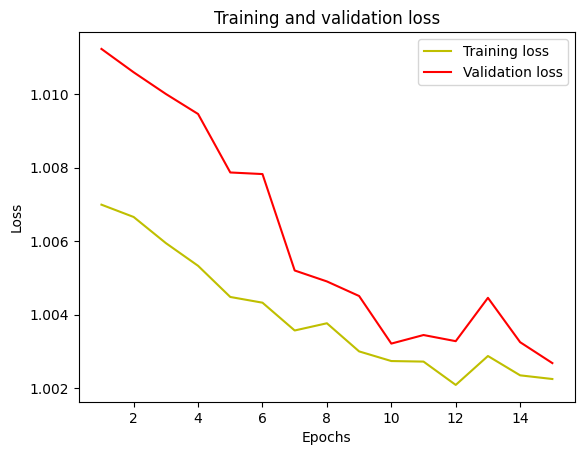

In [ ]:
history = history1
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
acc = history.history['jacard_coef']
print("Accuracy",acc)
val_acc = history.history['val_jacard_coef']
print("Validation Accuracy",val_acc)

Accuracy [0.21360941231250763, 0.2213164120912552, 0.22150008380413055, 0.22677677869796753, 0.2241235226392746, 0.23291055858135223, 0.21789033710956573, 0.24800549447536469, 0.22593526542186737, 0.23467755317687988, 0.24847853183746338, 0.2373998910188675, 0.23144765198230743, 0.223471000790596, 0.25404009222984314]
Validation Accuracy [0.18067772686481476, 0.17682985961437225, 0.17381034791469574, 0.16917912662029266, 0.17298880219459534, 0.16561175882816315, 0.18194922804832458, 0.17981335520744324, 0.18099160492420197, 0.1944691389799118, 0.19102902710437775, 0.1985892951488495, 0.18104377388954163, 0.1965399831533432, 0.20457737147808075]


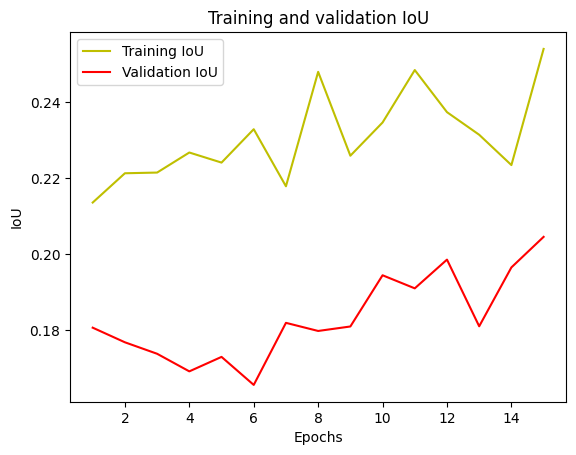

In [ ]:
plt.plot(epochs, acc, 'y', label='Training IoU')
plt.plot(epochs, val_acc, 'r', label='Validation IoU')
plt.title('Training and validation IoU')
plt.xlabel('Epochs')
plt.ylabel('IoU')
plt.legend()
plt.show()

In [ ]:
from keras.models import load_model
model1 = load_model("models/satellite_resnet_backbone_unet_15epochs.hdf5",
                   custom_objects={'dice_loss_plus_2focal_loss': total_loss,
                                   'jacard_coef':jacard_coef}, compile=False

)

#model = load_model("models/satellite_standard_unet_100epochs.hdf5", compile=False)

#Inetrsection Over Union.

In [ ]:
y_pred=model1.predict(X_test)
y_pred_argmax=np.argmax(y_pred, axis=3)
y_test_argmax=np.argmax(y_test, axis=3)

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


In [ ]:
from keras.metrics import MeanIoU
n_classes = 6
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(y_test_argmax, y_pred_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

Mean IoU = 0.112146385


#Predictions on few Sample Images.

In [ ]:
import random
test_img_number = random.randint(0, len(X_test))
test_img = X_test[test_img_number]
ground_truth=y_test_argmax[test_img_number]
#test_img_norm=test_img[:,:,0][:,:,None]
test_img_input=np.expand_dims(test_img, 0)
prediction = (model.predict(test_img_input))
predicted_img=np.argmax(prediction, axis=3)[0,:,:]


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step


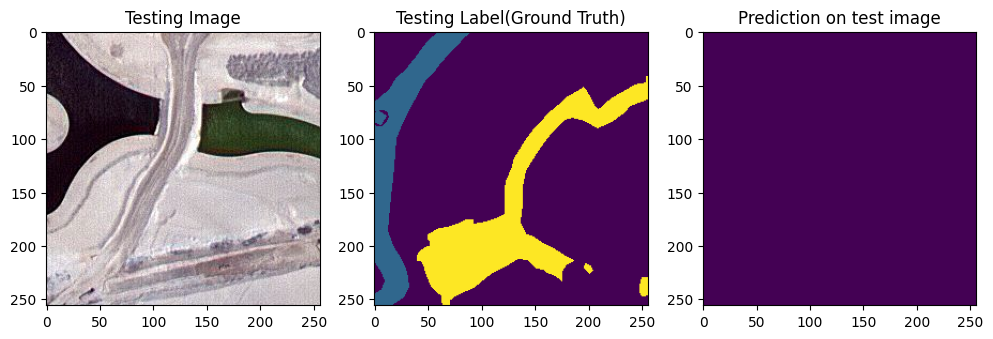

In [ ]:
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img)
plt.subplot(232)
plt.title('Testing Label(Ground Truth)')
plt.imshow(ground_truth)
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(predicted_img)
plt.show()

In [ ]:
import random
test_img_number = random.randint(0, len(X_test))
test_img = X_test[test_img_number]
ground_truth=y_test_argmax[test_img_number]
#test_img_norm=test_img[:,:,0][:,:,None]
test_img_input=np.expand_dims(test_img, 0)
prediction = (model.predict(test_img_input))
predicted_img=np.argmax(prediction, axis=3)[0,:,:]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step


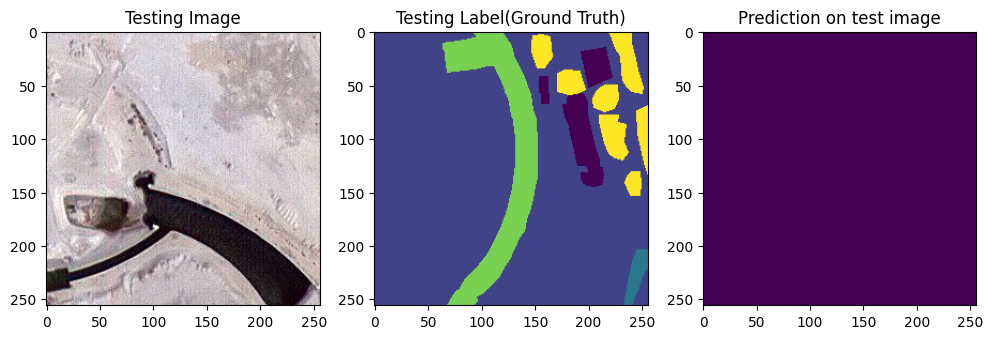

In [ ]:
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img)
plt.subplot(232)
plt.title('Testing Label(Ground Truth)')
plt.imshow(ground_truth)
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(predicted_img)
plt.show()

In [ ]:
from keras.models import load_model
model1 = load_model("/content/models/satellite_resnet_backbone_unet_15epochs.hdf5",
                   custom_objects={'dice_loss_plus_2focal_loss': total_loss,
                                   'jacard_coef':jacard_coef}, compile=False

)

#Inetrsection Over Union.

In [ ]:
y_pred=model1.predict(X_test)
y_pred_argmax=np.argmax(y_pred, axis=3)
y_test_argmax=np.argmax(y_test, axis=3)

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


In [ ]:
from keras.metrics import MeanIoU
n_classes = 6
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(y_test_argmax, y_pred_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

Mean IoU = 0.112146385


#Predictions on few Sample Images.

In [ ]:
import random
test_img_number = random.randint(0, len(X_test))
test_img = X_test[test_img_number]
ground_truth=y_test_argmax[test_img_number]
#test_img_norm=test_img[:,:,0][:,:,None]
test_img_input=np.expand_dims(test_img, 0)
prediction = (model1.predict(test_img_input))
predicted_img=np.argmax(prediction, axis=3)[0,:,:]

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


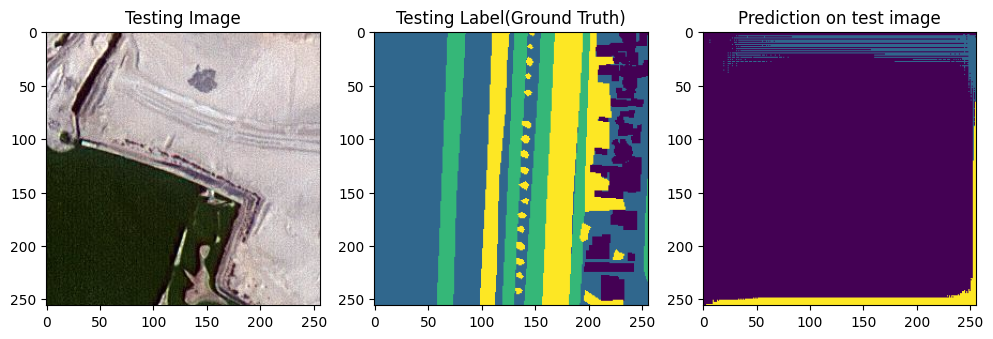

In [ ]:
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img)
plt.subplot(232)
plt.title('Testing Label(Ground Truth)')
plt.imshow(ground_truth)
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(predicted_img)
plt.show()

In [ ]:
import random
test_img_number = random.randint(0, len(X_test))
test_img = X_test[test_img_number]
ground_truth=y_test_argmax[test_img_number]
#test_img_norm=test_img[:,:,0][:,:,None]
test_img_input=np.expand_dims(test_img, 0)
prediction = (model1.predict(test_img_input))
predicted_img=np.argmax(prediction, axis=3)[0,:,:]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 704ms/step


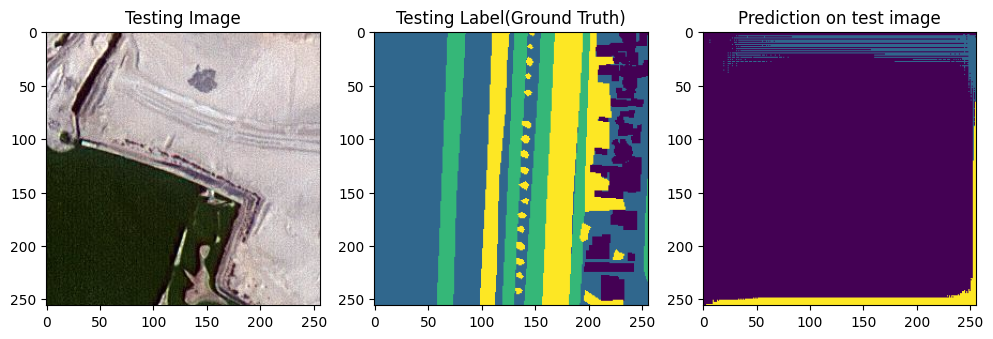

In [ ]:
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img)
plt.subplot(232)
plt.title('Testing Label(Ground Truth)')
plt.imshow(ground_truth)
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(predicted_img)
plt.show()

#